##### 1. Understand the demand decline and SKU behavior

In [1]:
# Step 1. Load and prepare the data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv("Inventory_Turnover.csv")

# Convert date column
df["dispense_date"] = pd.to_datetime(
    df["dispense_date"],
    dayfirst=True,
    format="mixed"
)

# Extract date attributes
df["year"] = df["dispense_date"].dt.year
df["month"] = df["dispense_date"].dt.month
df["month_name"] = df["dispense_date"].dt.strftime("%b")
df["year_month"] = df["dispense_date"].dt.to_period("M")

# Check data
print("Dataset shape:", df.shape)
print("Date range:", df["dispense_date"].min(),
      "to", df["dispense_date"].max())

print("Unique SKUs:", df["sku"].nunique())
print("Unique devices:", df["device_id"].nunique())

print(df.head())

Dataset shape: (38982, 9)
Date range: 2022-02-23 00:00:00 to 2024-02-23 00:00:00
Unique SKUs: 82
Unique devices: 5
                                sku dispense_date  \
0  05d98e5c2603bf927952aa3eb74d1fc3    2024-02-22   
1  05d98e5c2603bf927952aa3eb74d1fc3    2024-02-21   
2  05d98e5c2603bf927952aa3eb74d1fc3    2024-02-20   
3  05d98e5c2603bf927952aa3eb74d1fc3    2024-02-19   
4  05d98e5c2603bf927952aa3eb74d1fc3    2024-02-18   

                                 device_id  package_qty  qty_dispensed  year  \
0  device_0749c361d8ac7047c2f98fbcb2eadd16            1             20  2024   
1  device_0749c361d8ac7047c2f98fbcb2eadd16            1              9  2024   
2  device_0749c361d8ac7047c2f98fbcb2eadd16            1             15  2024   
3  device_0749c361d8ac7047c2f98fbcb2eadd16            1             13  2024   
4  device_0749c361d8ac7047c2f98fbcb2eadd16            1             24  2024   

   month month_name year_month  
0      2        Feb    2024-02  
1      2        Feb

year_month
2022-02-28     2947
2022-03-31    15283
2022-04-30    14378
2022-05-31    14793
2022-06-30    15607
2022-07-31    17530
2022-08-31    18077
2022-09-30    15119
2022-10-31    17266
2022-11-30    19581
2022-12-31    19943
2023-01-31    15702
2023-02-28     8068
2023-03-31     9356
2023-04-30     9330
2023-05-31    10054
2023-06-30    10001
2023-07-31    10401
2023-08-31    10796
2023-09-30     9865
2023-10-31    10546
2023-11-30    11379
2023-12-31    12053
2024-01-31    10567
2024-02-29     8886
Freq: ME, Name: qty_dispensed, dtype: int64


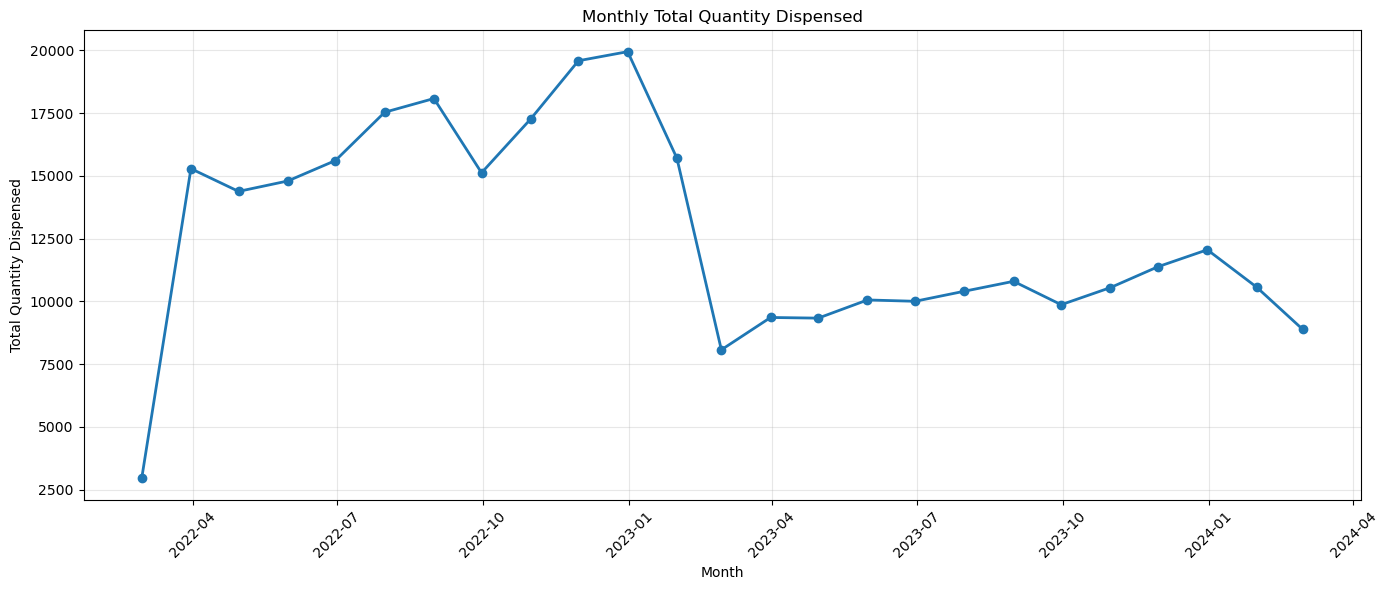

In [2]:
# Step 2. Examine the overall dispensing trend
monthly_demand = (
    df.groupby("year_month")["qty_dispensed"]
    .sum()
)

# Convert PeriodIndex to timestamps for plotting
monthly_demand.index = monthly_demand.index.to_timestamp("M")
print(monthly_demand)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_demand.index,
    monthly_demand.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Total Quantity Dispensed")
plt.xlabel("Month")
plt.ylabel("Total Quantity Dispensed")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Check the chart:
- Is demand generally declining?
- When does the decline become noticeable?
- Are there months with unusually high or low dispensing?
- Does demand appear to stabilize after the decline?

year
2022    167577
2023    103781
Name: qty_dispensed, dtype: int64
2022 Total: 167,577
2023 Total: 103,781
Absolute Change: -63,796
Percentage Change: -38.07%


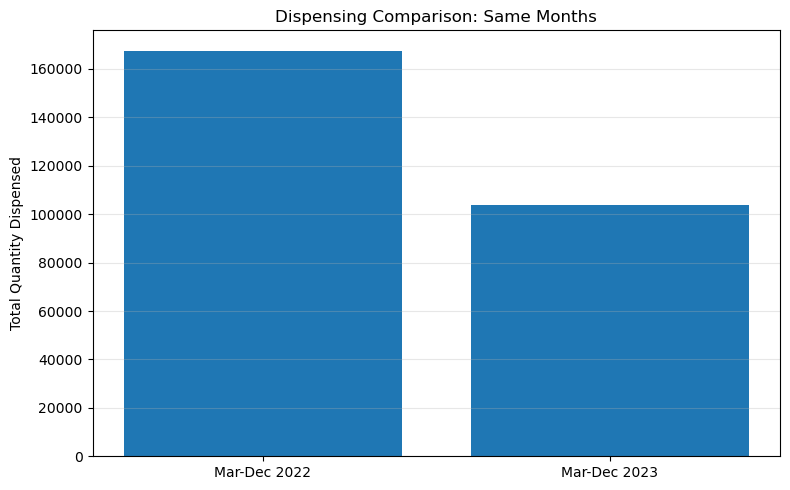

In [3]:
# Step 3. Compare March–December 2022 against March–December 2023
# Select March to December for 2022 and 2023
comparison_df = df[
    (df["year"].isin([2022, 2023])) &
    (df["month"].between(3, 12))
].copy()

# Total dispensing by year
yearly_comparison = (
    comparison_df.groupby("year")["qty_dispensed"]
    .sum()
)

print(yearly_comparison)

# Calculate percentage change
qty_2022 = yearly_comparison.loc[2022]
qty_2023 = yearly_comparison.loc[2023]

change = qty_2023 - qty_2022
change_pct = (change / qty_2022) * 100

print(f"2022 Total: {qty_2022:,.0f}")
print(f"2023 Total: {qty_2023:,.0f}")
print(f"Absolute Change: {change:,.0f}")
print(f"Percentage Change: {change_pct:.2f}%")

plt.figure(figsize=(8, 5))

plt.bar(
    ["Mar-Dec 2022", "Mar-Dec 2023"],
    [qty_2022, qty_2023]
)

plt.title("Dispensing Comparison: Same Months")
plt.ylabel("Total Quantity Dispensed")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Based on the chart numbers above, the March–December (2022 vs 2023) total declined by approximately 38.07%.

In [4]:
# Step 4. Identify which SKUs contributed to the decline
sku_yearly = (
    comparison_df
    .pivot_table(
        index="sku",
        columns="year",
        values="qty_dispensed",
        aggfunc="sum",
        fill_value=0
    )
)

# Make sure both year columns exist
sku_yearly = sku_yearly.reindex(
    columns=[2022, 2023],
    fill_value=0
)

# Calculate changes
sku_yearly["change_qty"] = (
    sku_yearly[2023] - sku_yearly[2022]
)

sku_yearly["change_pct"] = (
    sku_yearly["change_qty"] /
    sku_yearly[2022].replace(0, np.nan)
) * 100

print(sku_yearly.head())

year                              2022  2023  change_qty  change_pct
sku                                                                 
01bdf04bb36dfcd94a9ef6fce31afc59   314   109        -205  -65.286624
0294e9ff7bc77c29cdd83b6125ee4940  1766  1338        -428  -24.235561
0300087aca6bca74aea4cfa71bbb5adb  2950  1734       -1216  -41.220339
033b262dad9e437f1864d875e073b328   744   214        -530  -71.236559
05d98e5c2603bf927952aa3eb74d1fc3  7040  3136       -3904  -55.454545


In [5]:
# Identify the SKUs with the largest decreases.
top_declining_skus = (
    sku_yearly
    .sort_values("change_qty")
    .head(10)
)

print("Top 10 SKUs with the largest declines:")
print(top_declining_skus)

Top 10 SKUs with the largest declines:
year                               2022  2023  change_qty  change_pct
sku                                                                  
be61be55295db1941eaf232ee6288fa7   9815  4916       -4899  -49.913398
b1cfc8c80d03027941b0bce8d2ff3deb  11639  7177       -4462  -38.336627
05d98e5c2603bf927952aa3eb74d1fc3   7040  3136       -3904  -55.454545
2f621fea30f47fc68073c52acc1a1108   5718  1901       -3817  -66.754110
690b7d2f4218991b6496be8eb456a943   7220  3890       -3330  -46.121884
ff9575eadeeb732ad8095286dc2bff82   7268  3954       -3314  -45.597138
e2f0ae8b2db933987082ffb201f5a5ed   5434  2502       -2932  -53.956570
93d664dddeea2dd49decf97035051e92   8134  5484       -2650  -32.579297
af90bd893233dab67c0e4adcf04fca82   3779  1365       -2414  -63.879333
abc8b5d901bd3d2178a6ae3c7392227d   4822  2484       -2338  -48.486105


In [6]:
# And the SKUs with the largest increases:
top_increasing_skus = (
    sku_yearly
    .sort_values("change_qty", ascending=False)
    .head(10)
)

print("Top 10 SKUs with the largest increases:")
print(top_increasing_skus)

Top 10 SKUs with the largest increases:
year                              2022  2023  change_qty  change_pct
sku                                                                 
a6d4efc4d6cd6002d8865e38a2cfe3f2     0   411         411         NaN
82105f54039064dbddc2d59efa5377be   843  1024         181   21.470937
66133559e0f832da8500b2127d18f9dc   479   626         147   30.688935
16eff917bdf1fbe64883aa4bb8b4a1f8   418   528         110   26.315789
cf7905882011327f64f363146d2967cb   409   432          23    5.623472
1a9216218ce8ca818adb55ba1cc963c4    22    36          14   63.636364
48d1f3625ed89240b0c15486880eb40a     0     9           9         NaN
df1f227ca6f5a237e8c15dd1311183e0    17    24           7   41.176471
9a154810b166b91ae0c3d0cd84fb7e05  6811  6817           6    0.088093
a5d00bb12cd51265c8d3b0b447d85964   104   104           0    0.000000


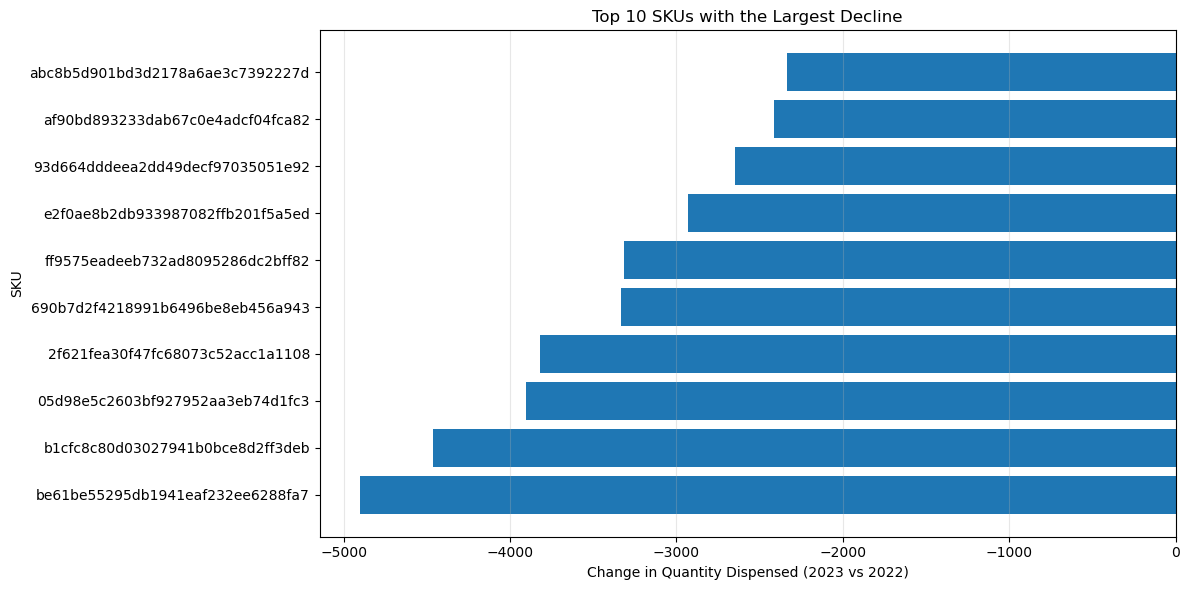

In [7]:
# Which products contributed most to the total decline
plot_data = top_declining_skus.sort_values("change_qty")

plt.figure(figsize=(12, 6))

plt.barh(
    plot_data.index,
    plot_data["change_qty"]
)

plt.title("Top 10 SKUs with the Largest Decline")
plt.xlabel("Change in Quantity Dispensed (2023 vs 2022)")
plt.ylabel("SKU")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

demand_status
Decreased    70
Increased     9
Unchanged     1
Name: count, dtype: int64


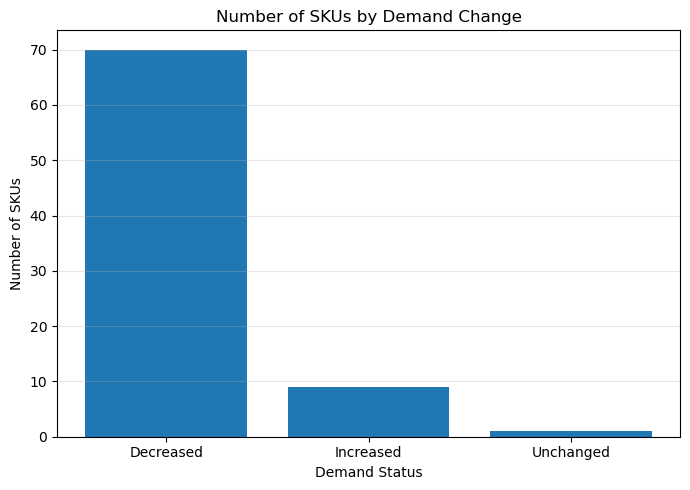

In [8]:
# Step 5. Determine whether the decline is widespread
sku_yearly["demand_status"] = np.select(
    [
        sku_yearly["change_qty"] > 0,
        sku_yearly["change_qty"] < 0
    ],
    [
        "Increased",
        "Decreased"
    ],
    default="Unchanged"
)

status_counts = sku_yearly["demand_status"].value_counts()

print(status_counts)

plt.figure(figsize=(7, 5))

plt.bar(
    status_counts.index,
    status_counts.values
)

plt.title("Number of SKUs by Demand Change")
plt.xlabel("Demand Status")
plt.ylabel("Number of SKUs")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

year                                      2022   2023  change_qty  change_pct
device_id                                                                    
device_6726f2a054f54836aaabe8c7643286bc  39249  21908      -17341  -44.182017
device_0749c361d8ac7047c2f98fbcb2eadd16  33728  16555      -17173  -50.916153
device_65ae7ea424c57d46ac409256fe359349  36271  21462      -14809  -40.828761
device_c287be7e02167387bf9e7eca061ce5b5  30365  20585       -9780  -32.208134
device_af645ebf4c96eb6e430529a2a9913686  27964  23271       -4693  -16.782292


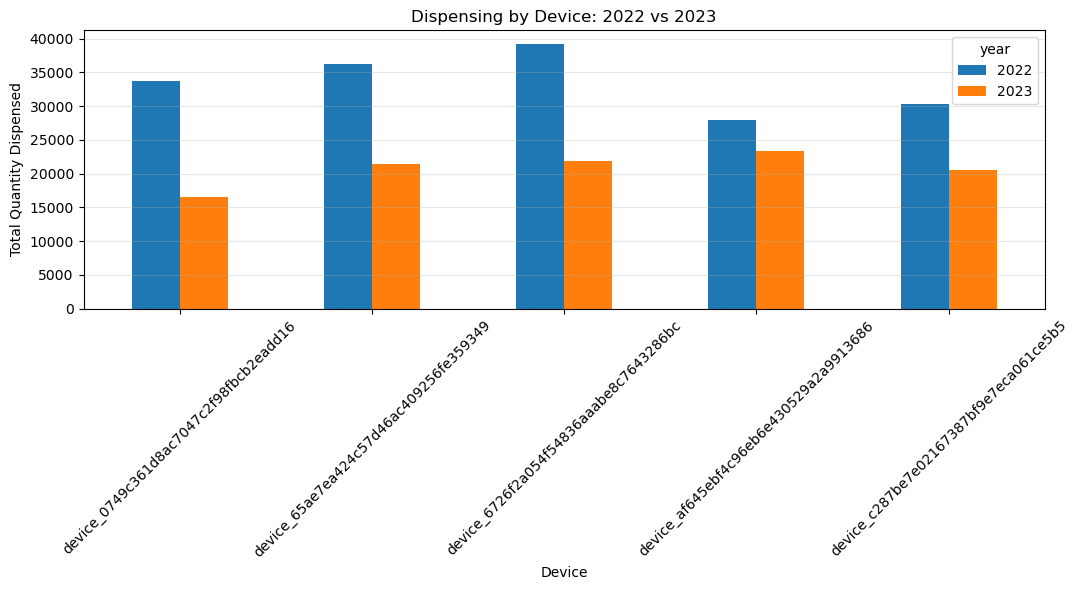

In [9]:
# Step 6. Investigate demand changes by device
device_yearly = (
    comparison_df
    .pivot_table(
        index="device_id",
        columns="year",
        values="qty_dispensed",
        aggfunc="sum",
        fill_value=0
    )
)

device_yearly = device_yearly.reindex(
    columns=[2022, 2023],
    fill_value=0
)

device_yearly["change_qty"] = (
    device_yearly[2023] - device_yearly[2022]
)

device_yearly["change_pct"] = (
    device_yearly["change_qty"] /
    device_yearly[2022].replace(0, np.nan)
) * 100

print(device_yearly.sort_values("change_qty"))

device_yearly[[2022, 2023]].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Dispensing by Device: 2022 vs 2023")
plt.xlabel("Device")
plt.ylabel("Total Quantity Dispensed")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

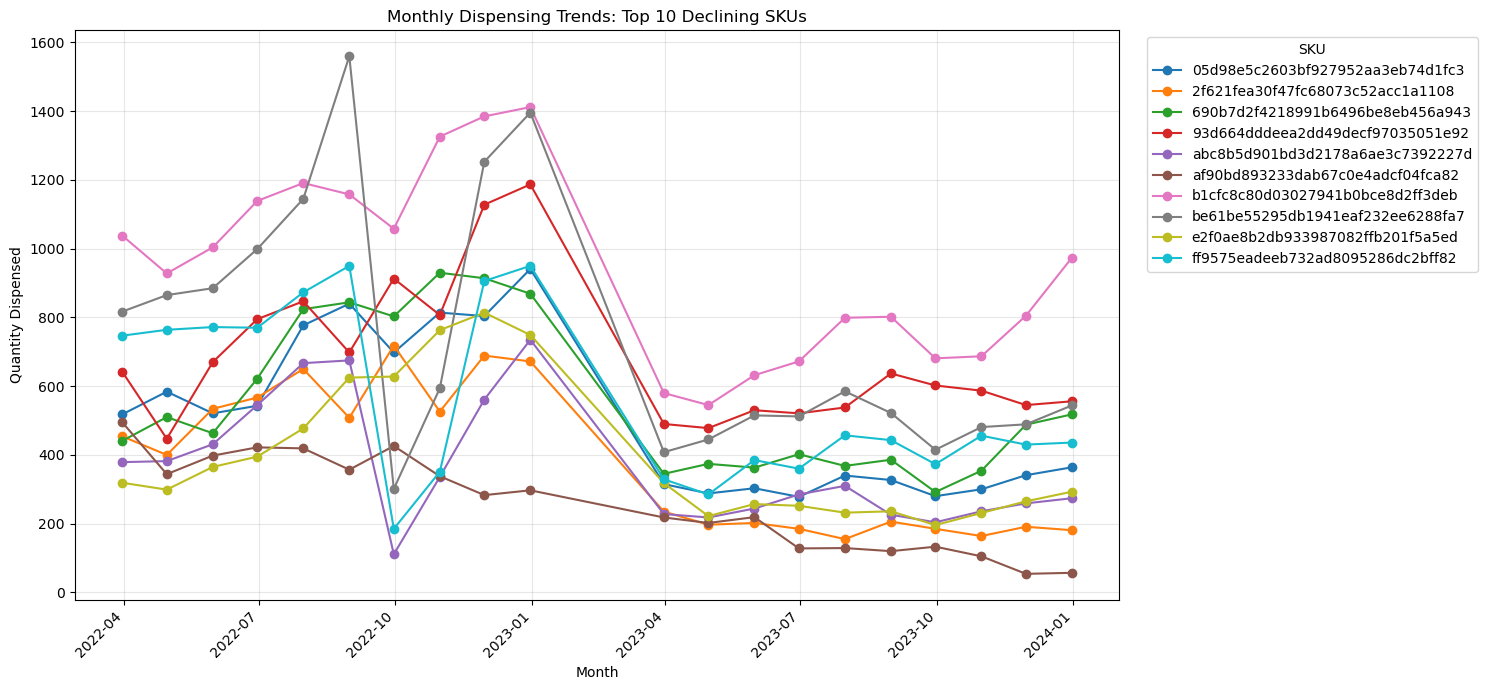

In [10]:
# Step 7. Examine individual SKU trends over time
top_10_skus = top_declining_skus.index.tolist()

sku_monthly = (
    comparison_df[
        comparison_df["sku"].isin(top_10_skus)
    ]
    .groupby(["year_month", "sku"])["qty_dispensed"]
    .sum()
    .unstack(fill_value=0)
)

sku_monthly.index = sku_monthly.index.to_timestamp("M")

sku_monthly.plot(
    figsize=(15, 7),
    marker="o"
)

plt.title("Monthly Dispensing Trends: Top 10 Declining SKUs")
plt.xlabel("Month")
plt.ylabel("Quantity Dispensed")
plt.xticks(rotation=45)
plt.legend(title="SKU", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Step 8. Create a consolidated SKU analysis table
# Aggregate monthly quantities per SKU
sku_monthly_all = (
    df.groupby(["sku", "year_month"])["qty_dispensed"]
    .sum()
    .unstack(fill_value=0)
)

# Descriptive statistics across observed months
sku_stats = pd.DataFrame(index=sku_monthly_all.index)

sku_stats["total_qty"] = sku_monthly_all.sum(axis=1)
sku_stats["mean_monthly_qty"] = sku_monthly_all.mean(axis=1)
sku_stats["median_monthly_qty"] = sku_monthly_all.median(axis=1)
sku_stats["std_monthly_qty"] = sku_monthly_all.std(axis=1)

sku_stats["cv"] = (
    sku_stats["std_monthly_qty"] /
    sku_stats["mean_monthly_qty"].replace(0, np.nan)
)

# Number of months with recorded dispensing
sku_stats["active_months"] = (
    sku_monthly_all.gt(0).sum(axis=1)
)

# Add annual comparison results
sku_analysis = sku_stats.join(
    sku_yearly[
        [2022, 2023, "change_qty", "change_pct", "demand_status"]
    ]
)

# Add assigned device
sku_device = df.groupby("sku")["device_id"].first()
sku_analysis["device_id"] = sku_device

# Sort by total quantity dispensed
sku_analysis = sku_analysis.sort_values(
    "total_qty",
    ascending=False
)

print(sku_analysis.round(2).to_string())

sku_analysis.to_csv("SKU_Demand_Analysis.csv")

                                  total_qty  mean_monthly_qty  median_monthly_qty  std_monthly_qty    cv  active_months     2022    2023  change_qty  change_pct demand_status                                device_id
sku                                                                                                                                                                                                                    
b1cfc8c80d03027941b0bce8d2ff3deb      21845            873.80               805.0           302.34  0.35             25  11639.0  7177.0     -4462.0      -38.34     Decreased  device_6726f2a054f54836aaabe8c7643286bc
be61be55295db1941eaf232ee6288fa7      17273            690.92               544.0           354.58  0.51             25   9815.0  4916.0     -4899.0      -49.91     Decreased  device_0749c361d8ac7047c2f98fbcb2eadd16
93d664dddeea2dd49decf97035051e92      16395            655.80               594.0           239.79  0.37             25   8134.0  5484.0

OVERALL DISPENSING CHANGE
2022: 167,577
2023: 103,781
Change: -63,796 (-38.07%)

SKU SUMMARY
status
Decreased    70
Increased     9
Unchanged     1
Name: count, dtype: int64
Top 10 SKUs' share of gross decreases: 52.64%

TOP 10 DECLINING SKUs
year                               2022  2023  change     status
sku                                                             
be61be55295db1941eaf232ee6288fa7   9815  4916   -4899  Decreased
b1cfc8c80d03027941b0bce8d2ff3deb  11639  7177   -4462  Decreased
05d98e5c2603bf927952aa3eb74d1fc3   7040  3136   -3904  Decreased
2f621fea30f47fc68073c52acc1a1108   5718  1901   -3817  Decreased
690b7d2f4218991b6496be8eb456a943   7220  3890   -3330  Decreased
ff9575eadeeb732ad8095286dc2bff82   7268  3954   -3314  Decreased
e2f0ae8b2db933987082ffb201f5a5ed   5434  2502   -2932  Decreased
93d664dddeea2dd49decf97035051e92   8134  5484   -2650  Decreased
af90bd893233dab67c0e4adcf04fca82   3779  1365   -2414  Decreased
abc8b5d901bd3d2178a6ae3c7392227d   4822  2

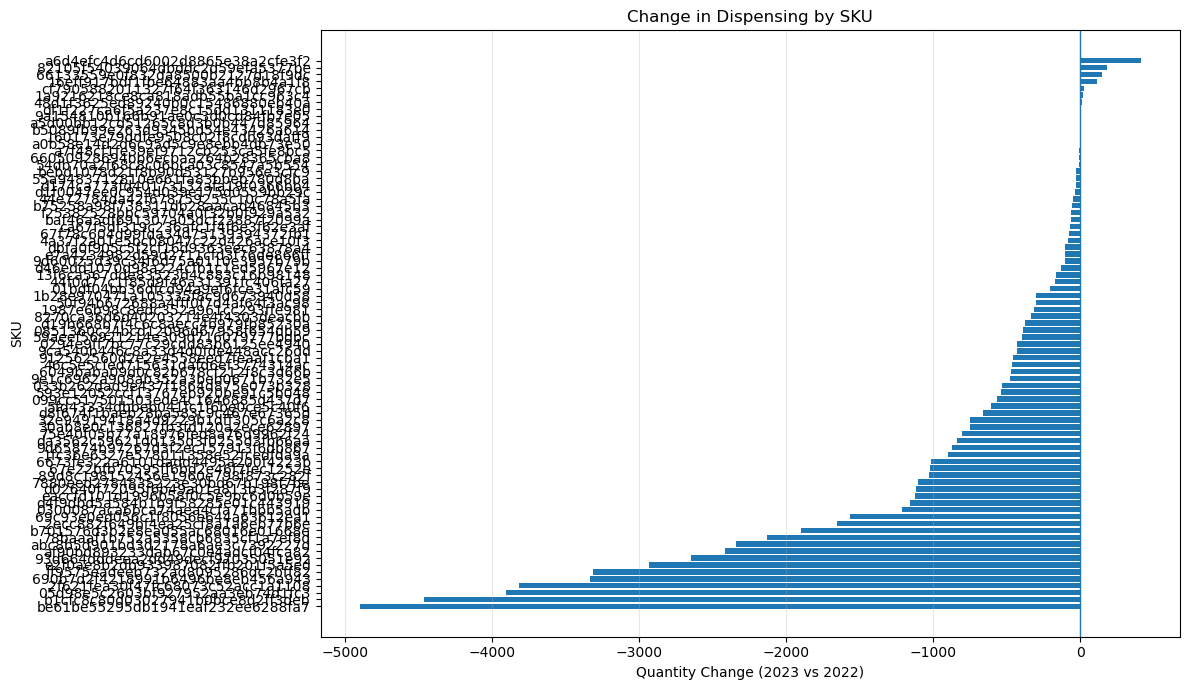

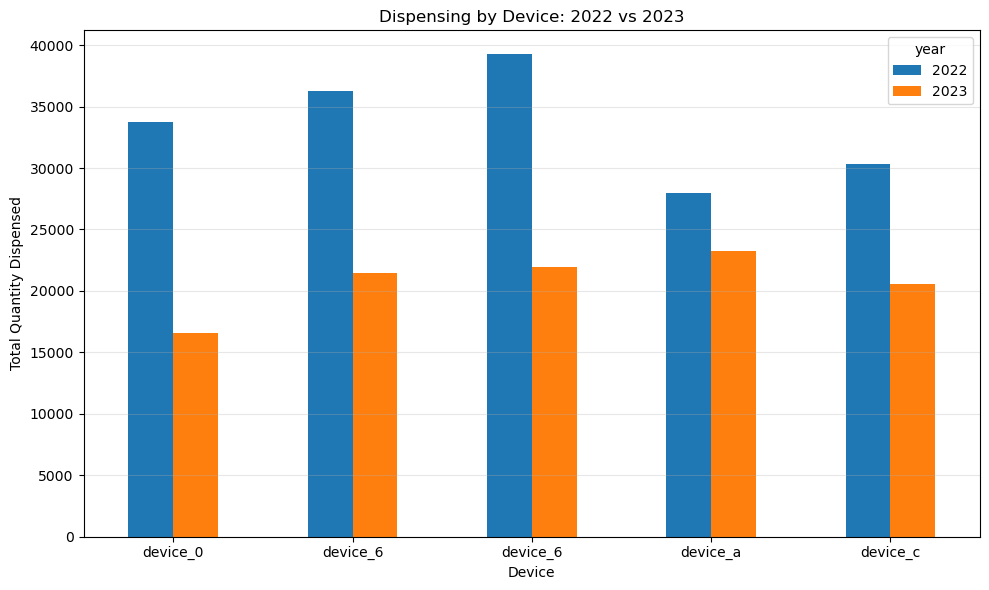

In [ ]:
# Summary - Change in Dispensing by SKU and by Device
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load and prepare
df = pd.read_csv("Inventory_Turnover.csv")

df["dispense_date"] = pd.to_datetime(
    df["dispense_date"],
    dayfirst=True,
    format="mixed"
)

df["year"] = df["dispense_date"].dt.year
df["month"] = df["dispense_date"].dt.month

# Compare identical months: March to December
comp = df[
    df["year"].isin([2022, 2023]) &
    df["month"].between(3, 12)
].copy()

# Overall comparison
overall = comp.groupby("year")["qty_dispensed"].sum()

net_change = overall[2023] - overall[2022]
net_change_pct = net_change / overall[2022] * 100

print("OVERALL DISPENSING CHANGE")
print(f"2022: {overall[2022]:,.0f}")
print(f"2023: {overall[2023]:,.0f}")
print(f"Change: {net_change:,.0f} ({net_change_pct:.2f}%)")


# ---------------------------------
# SKU CONTRIBUTION
# ---------------------------------

sku = comp.pivot_table(
    index="sku",
    columns="year",
    values="qty_dispensed",
    aggfunc="sum",
    fill_value=0
).reindex(columns=[2022, 2023], fill_value=0)

sku["change"] = sku[2023] - sku[2022]

sku["status"] = np.select(
    [sku["change"] < 0, sku["change"] > 0],
    ["Decreased", "Increased"],
    default="Unchanged"
)

sku_counts = sku["status"].value_counts()

gross_decrease = -sku.loc[sku["change"] < 0, "change"].sum()

top10 = sku.sort_values("change").head(10)

top10_share = (
    -top10["change"].sum() / gross_decrease * 100
)

print("\nSKU SUMMARY")
print(sku_counts)
print(f"Top 10 SKUs' share of gross decreases: {top10_share:.2f}%")

print("\nTOP 10 DECLINING SKUs")
print(top10)


# ---------------------------------
# DEVICE CONTRIBUTION
# ---------------------------------

device = comp.pivot_table(
    index="device_id",
    columns="year",
    values="qty_dispensed",
    aggfunc="sum",
    fill_value=0
).reindex(columns=[2022, 2023], fill_value=0)

device["change"] = device[2023] - device[2022]

device["change_pct"] = (
    device["change"] / device[2022] * 100
)

# Shorten device IDs for readability
device.index = device.index.str[:8]

print("\nDEVICE SUMMARY")
print(device.round(2))


# ---------------------------------
# CHART 1: SKU CHANGES
# ---------------------------------

plot_sku = sku.sort_values("change")

plt.figure(figsize=(12, 7))

plt.barh(
    plot_sku.index,
    plot_sku["change"]
)

plt.title("Change in Dispensing by SKU")
plt.xlabel("Quantity Change (2023 vs 2022)")
plt.ylabel("SKU")

plt.axvline(0, linewidth=1)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


# ---------------------------------
# CHART 2: DEVICE COMPARISON
# ---------------------------------

device[[2022, 2023]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Dispensing by Device: 2022 vs 2023")
plt.xlabel("Device")
plt.ylabel("Total Quantity Dispensed")

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Main finding:**  
The decline is widespread across products and devices, rather than being caused by just one SKU or one vending machine.
1. Broad change in dispensing behavior — strongest evidence. Most SKUs declined, and all five devices declined.
2. A few high-volume SKUs contributed disproportionately. The ten largest declining SKUs account for about half of the gross decreases, so they deserve individual investigation.
3. A single-device problem — least supported. No device maintained or increased its dispensing volume.
However, we cannot yet conclude that actual user demand decreased. Reduced dispensing could also be caused by stockouts, changes in machine availability, changes in operating activity, or other operational factors.

### **More Investigations**

**1. Restocking**  
Relationship between restocking and dispensing.  
Restock Orders and Dispensing Quantities by device and month for March 2023–February 2024.
<table>
  <tr>
    <th>Comparison</th>
    <th>Correlation with dispensing quantity</th>
  </tr>
  <tr>
    <td>Restock order count</td>
    <td>0.27</td>
  </tr>
  <tr>
    <td>Restock monetary value</td>
    <td>0.69</td>
  </tr>
</table>

The order-count relationship is weak, while the monetary-value relationship is more noticeable. But this is only an exploratory association across 60 device-month observations. It does not show that higher restocking caused higher dispensing. *Order value can reflect product mix and prices as well as replenishment volume.*

**Finding:** There is no clear evidence of a general reduction in restocking frequency. SKU-level stock availability remains unverified.

**2. Dispensing frequency**  
Compared the same ten months in 2022 and 2023. Since the inventory file has no unique transaction ID, the number of recorded rows is used as a proxy for dispensing frequency. Each row represents a recorded SKU, device and dispensing-date entry.
<table>
    <tr>
    <th>Quantity versus dispensing records</th>
    </tr>
    <tr>
    <td>Total quantity dispensed</td>
    <td>−38.1%</td>
    </tr>
    <tr>
    <td>Number of recorded rows</td>
    <td>−9.5%</td>
    </tr>
</table>  
_
<table>
    <tr>
    <th>Measure</th>
    <th>Mar–Dec 2022</th>
    <th>Mar–Dec 2023</th>
    </tr>
    <tr>
    <td>Quantity dispensed</td>
    <td>167,577</td>
    <td>103,781</td>
    </tr>
    <tr>
    <td>Recorded rows</td>
    <td>17,320</td>
    <td>15,683</td>
    </tr>
    <tr>
    <td>Quantity per row</td>
    <td>9.68</td>
    <td>6.62</td>
    </tr>
    <tr>
    <td>Rows per calendar day</td>
    <td>56.60</td>
    <td>51.25</td>
    </tr>
</table>
  
The average quantity per recorded row fell by approximately 31.6%.

This is a major distinction:
- There were fewer recorded dispensing entries, but the reduction was relatively modest.
- The quantity dispensed per entry fell much more sharply.
The decline therefore appears to involve smaller quantities per recorded dispensing entry, in addition to fewer entries.

This does not necessarily mean that users took smaller quantities in each individual transaction: without a transaction identifier, a row may not represent a complete transaction.

**3. SKU availability**  
Overall SKU presence
<table>
  <tr>
    <th>Measure</th>
    <th>Result</th>
  </tr>
  <tr>
    <td>SKUs with activity in either matched period</td>
    <td>80</td>
  </tr>
  <tr>
    <td>SKUs present in both periods</td>
    <td>76</td>
  </tr>
  <tr>
    <td>SKUs present in 2022 but absent in 2023</td>
    <td>2</td>
  </tr>
  <tr>
    <td>SKUs absent in 2022 but present in 2023</td>
    <td>2</td>
  </tr>
  <tr>
    <td>SKUs with lower total quantity in 2023</td>
    <td>70</td>
  </tr>
  <tr>
    <td>SKUs with higher total quantity in 2023</td>
    <td>9</td>
  </tr>
  <tr>
    <td>SKUs with unchanged quantity</td>
    <td>1</td>
  </tr>
</table>

The two SKUs that disappeared from the records had combined 2022 dispensing of only __2,148 units__. That is a small part of the overall decline of 63,796 units.

More importantly, **65 of the 80 SKUs were active in every one of the ten matched months in both years.**

The number of active SKUs per month also remained relatively stable:
- March 2022: 78
- March 2023: 73
- June 2023: 76
- December 2023: 75
- February 2024: 77

There is no sign of a major collapse in the number of SKUs represented in dispensing records.

**What does this tell us?**  
The decline is not primarily explained by products disappearing from the recorded dispensing activity.

Most SKUs continued to appear, but their dispensed quantities were lower. This supports the interpretation that the change affected the quantities dispensed across the product range.

There is still a distinction between a SKU being present in dispensing records and being available throughout the month. A SKU could be unavailable for several days and still have recorded dispensing later. We cannot measure that from this file.

**Finding:** SKU discontinuation or disappearance explains only a small part of the decline. Lower dispensing quantities across continuing SKUs are much more important.

**4. Device operation**  
I used recorded dispensing dates as a proxy for device activity. This is not a substitute for machine uptime or telemetry, but it can reveal long periods with no recorded dispensing.

Days with recorded dispensing
<table>
    <tr>
    <th>Device</th>
    <th>Active days, Mar–Dec 2022</th>
    <th>Active days, Mar–Dec 2023</th>
    </tr>
    <tr>
    <td>0749c361</td>
    <td>304</td>
    <td>305</td>
    </tr>
    <tr>
    <td>65ae7ea4</td>
    <td>300</td>
    <td>305</td>
    </tr>
    <tr>
    <td>6726f2a0</td>
    <td>304</td>
    <td>305</td>
    </tr>
    <tr>
    <td>af645ebf</td>
    <td>304</td>
    <td>305</td>
    </tr>
    <tr>
    <td>c287be7e</td>
    <td>299</td>
    <td>304</td>
    </tr>
</table>  
The comparison period contains 306 calendar days.

All five devices recorded dispensing on almost every day in both years. In 2023, no device had more than one consecutive day without a recorded dispensing entry during the matched period. In 2022, the longest such gap was two days.

This is not consistent with a prolonged device shutdown being the main explanation for the decline.

It is also worth noting that the number of active dispensing days actually increased slightly for several devices in 2023, even while their total quantities fell substantially.

**Finding:** The available evidence does not point to widespread device inactivity or prolonged shutdowns. However, a machine can be online and still have restricted product availability, reduced user traffic, or other operational changes.

**5. Combined interpretation**  
Here is how the four investigations fit together.
<table>
  <tr>
    <th>Investigation</th>
    <th>Main observation</th>
    <th>Assessment</th>
  </tr>
  <tr>
    <td>Restocking</td>
    <td>Order counts and values did not collapse after March 2023</td>
    <td>No obvious reduction in restocking activity</td>
  </tr>
  <tr>
    <td>Dispensing frequency</td>
    <td>Recorded rows fell 9.5%, while quantity per row fell 31.6%</td>
    <td>Strong evidence of smaller recorded dispensing quantities</td>
  </tr>
  <tr>
    <td>SKU availability</td>
    <td>76 of 80 SKUs appeared in both periods; 65 were active every month</td>
    <td>SKU disappearance is not the main cause</td>
  </tr>
  <tr>
    <td>Device operation</td>
    <td>All five devices recorded dispensing on nearly every day</td>
    <td>No evidence of prolonged widespread shutdown</td>
  </tr>
</table>


### **Overall conclusion**

The strongest evidence points to a broad reduction in the quantity dispensed per recorded entry, across most SKUs and all five devices.

The data does not support a conclusion that the decline was mainly caused by fewer active products, reduced restocking frequency, or prolonged machine shutdowns.

The remaining possibilities include changes in user consumption, quantities dispensed per occasion, operating demand at the sites, product availability within individual months, or dispensing policy changes.